# 02 · Baseline de rendimiento

Antes de optimizar, fijamos **el piso que cualquier modelo debe superar**:

1. `Dummy`: predice siempre la proporción de informales (AUC = 0.5).
2. **Regla de negocio** simple, sin ML: *"informal si no tiene contrato o trabaja por cuenta propia"*.
3. **Regresión logística** con el mismo preprocesamiento del proyecto.

Todo se evalúa en el **test fuera de tiempo** (enero–febrero 2026).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from informalidad.config import use_project_root
use_project_root()  # rutas relativas desde la raíz del proyecto

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
AZUL, NARANJA, GRIS = "#2a6fbb", "#e07b39", "#8a94a6"
pd.set_option("display.float_format", "{:,.4f}".format)

In [2]:
from informalidad.data import load_dataset, temporal_split, validate_dataset
from informalidad.models.evaluate import compute_metrics
from informalidad.models.candidates import candidate_models
from informalidad.config import raw_feature_columns

df, reporte = validate_dataset(load_dataset())
splits = temporal_split(df)
print("Validación:", reporte.as_dict())
print("Tamaños:", splits.sizes())

Validación: {'n_rows_in': 287900, 'n_rows_out': 287900, 'dropped_fraction': 0.0, 'dropped_nulls': 0, 'dropped_range_EDAD': 0, 'dropped_range_HORAS_SEMANA': 0, 'dropped_range_INGRESO_LABORAL': 0, 'dropped_domain_SEXO': 0, 'dropped_domain_NIVEL_EDUCATIVO': 0, 'dropped_domain_ESTADO_CIVIL': 0, 'dropped_domain_AFILIADO_SALUD': 0, 'dropped_domain_POSICION_OCUPACIONAL': 0, 'dropped_domain_TIENE_CONTRATO': 0, 'dropped_domain_RAMA_ACTIVIDAD': 0}
Tamaños: {'n_train': 184533, 'n_valid': 46134, 'n_test': 57233}


In [3]:
X_train, y_train = splits.train[raw_feature_columns()], splits.train["INFORMAL"]
X_test, y_test = splits.test[raw_feature_columns()], splits.test["INFORMAL"]

resultados = {}

# 1) Dummy
dummy = candidate_models()["baseline_dummy"].fit(X_train, y_train)
resultados["Dummy (proporción)"] = compute_metrics(y_test, dummy.predict_proba(X_test)[:, 1])

# 2) Regla de negocio (score 0/1, sin entrenamiento)
regla = ((X_test["TIENE_CONTRATO"] == 2) | (X_test["POSICION_OCUPACIONAL"] == 4)).astype(float)
resultados["Regla: sin contrato o cuenta propia"] = compute_metrics(y_test, regla)

# 3) Regresión logística
logreg = candidate_models()["logistic_regression"].fit(X_train, y_train)
resultados["Regresión logística"] = compute_metrics(y_test, logreg.predict_proba(X_test)[:, 1])

baseline = pd.DataFrame(resultados).T[["roc_auc", "pr_auc", "f1", "precision", "recall", "accuracy"]]
baseline

,roc_auc,pr_auc,f1,precision,recall,accuracy
Dummy (proporción),0.5000,0.5556,0.7143,0.5556,1.0000,0.5556
Regla: sin contrato o cuenta propia,0.7541,0.7424,0.7509,0.8274,0.6874,0.7466
Regresión logística,0.9517,0.9590,0.8902,0.9179,0.8641,0.8815


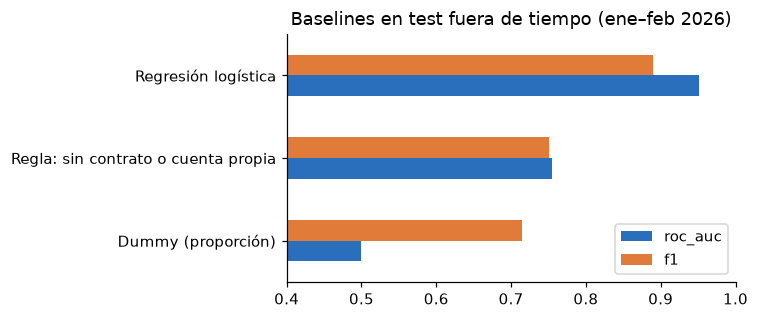

In [4]:
fig, ax = plt.subplots(figsize=(7, 3))
baseline[["roc_auc", "f1"]].plot.barh(ax=ax, color=[AZUL, NARANJA])
ax.set_xlim(0.4, 1); ax.set_title("Baselines en test fuera de tiempo (ene–feb 2026)")
fig.tight_layout()

## Conclusión

- La **regla de negocio** (sin ML) llega a AUC ≈ 0.75 y F1 ≈ 0.75: contrato y posición ayudan,
  pero se queda corta (deja por fuera ~31 % de los informales). Combinar todas las variables aporta mucho.
- La **regresión logística** ya salta a AUC ≈ 0.952 y F1 ≈ 0.89: es el baseline de ML a superar.
- **Métricas de éxito del proyecto** (en test fuera de tiempo):
  - ROC-AUC ≥ 0.95 y al menos +0.01 sobre la regresión logística.
  - F1 de la clase informal ≥ 0.90 (equilibrio entre no dejar por fuera informales y no
    gastar recursos en formales).